Dataset Shape: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Missing Values: 0

Class Distribu

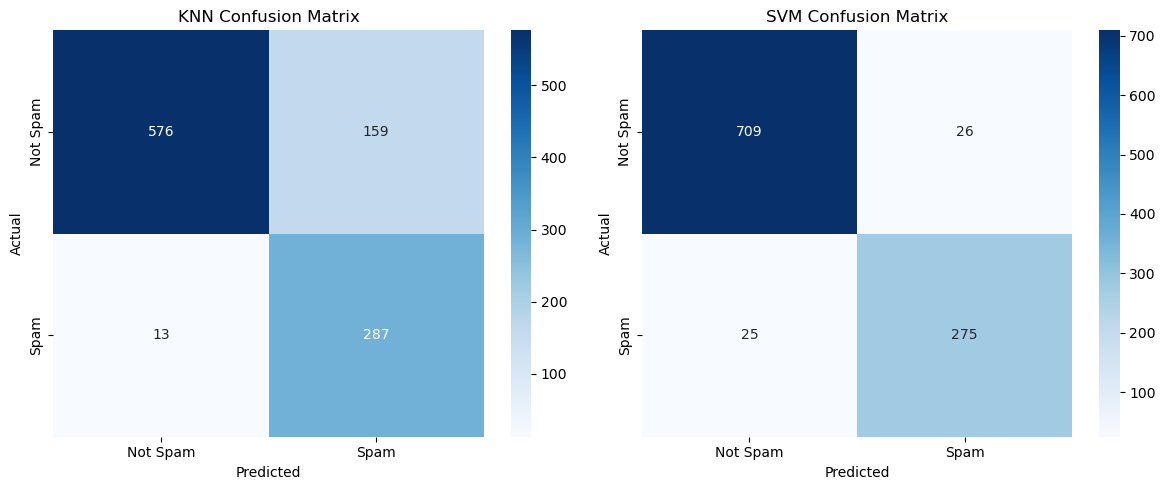


KNN Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


SVM Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



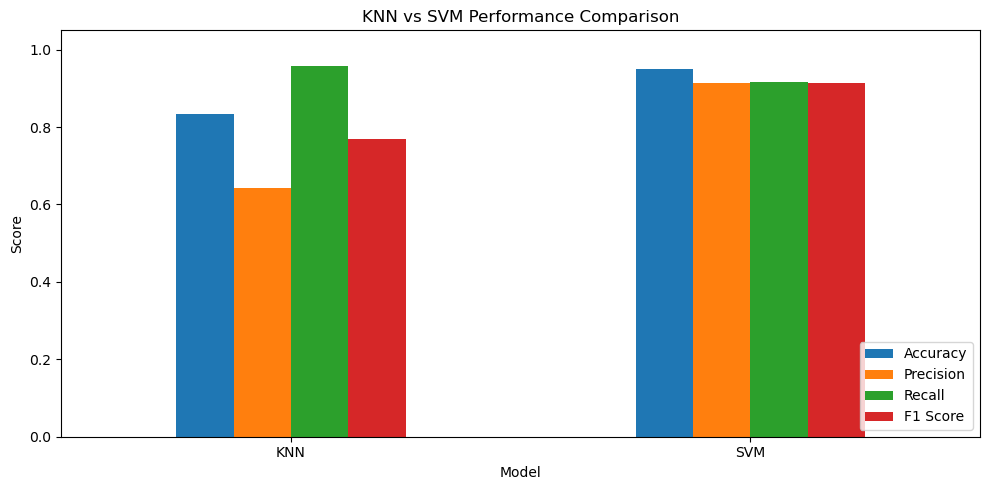

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# 1. Load Dataset
df = pd.read_csv("emails.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print("\nMissing Values:", df.isnull().sum().sum())

# 2. Data Preprocessing
df.drop_duplicates(inplace=True)
df.fillna(0, inplace=True)

# Remove email identifier
df.drop(columns=['Email No.'], errors='ignore', inplace=True)

# Separate features and target
X = df.drop(columns=['Prediction'])
y = df['Prediction']

print("\nClass Distribution:")
print(y.value_counts())

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize Features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. K-Nearest Neighbors Classification
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

# 5. Support Vector Machine Classification
svm = SVC(kernel='linear', random_state=42)

svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

# 6. Model Evaluation
def evaluate_model(y_test, y_pred):
    return [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]

knn_results = evaluate_model(y_test, knn_pred)
svm_results = evaluate_model(y_test, svm_pred)

# 7. Compare Performance
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [knn_results[0], svm_results[0]],
    'Precision': [knn_results[1], svm_results[1]],
    'Recall': [knn_results[2], svm_results[2]],
    'F1 Score': [knn_results[3], svm_results[3]]
})

print("\nModel Performance Comparison:")
print(results.to_string(index=False))

# 8. Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, name in zip(
    axes,
    [knn_pred, svm_pred],
    ['KNN', 'SVM']
):
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Spam', 'Spam'],
        yticklabels=['Not Spam', 'Spam'],
        ax=ax
    )

    ax.set_title(name + ' Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# 9. Classification Report
print("\nKNN Classification Report:")
print(classification_report(y_test, knn_pred))

print("\nSVM Classification Report:")
print(classification_report(y_test, svm_pred))

# 10. Performance Comparison Graph
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("KNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()
